In [1]:
# نصب کتابخانه‌ها در صورت نیاز

import sys
import subprocess
import importlib.util

required_packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
    "sklearn": "scikit-learn",
    "joblib": "joblib",
}

for module_name, package_name in required_packages.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {package_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", package_name]
        )

print("All required packages are available.")

All required packages are available.


In [2]:
from pathlib import Path
from itertools import combinations
import gc
import json
import math
import os
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 250)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 180)

RANDOM_STATE_MODEL = 142
np.random.seed(42)

In [3]:
# Portable configuration (repository root or notebooks/ working directory)
REPO_ROOT = Path(os.environ.get("FORCE_REPO_ROOT", Path.cwd())).expanduser().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if not (REPO_ROOT / "notebooks").is_dir():
    raise FileNotFoundError(
        "Repository root not found. Open Jupyter from the repository root "
        "or notebooks/, or set FORCE_REPO_ROOT to the repo path."
    )
DATA_DIR = Path(os.environ.get("FORCE_DATA_DIR", str(REPO_ROOT / "data" / "raw"))).expanduser().resolve()
PREPARED_DIR = Path(os.environ.get("FORCE_PREPARED_DIR", str(REPO_ROOT / "data" / "prepared"))).expanduser().resolve()
RESULTS_ROOT = Path(os.environ.get("FORCE_RESULTS_DIR", str(REPO_ROOT / "outputs"))).expanduser().resolve()

TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
PROJECT_ROOT = RESULTS_ROOT
OUTPUT_DIR = PROJECT_ROOT / "02A_legacy_RF_exact_reproduction"

PLOT_DIR = OUTPUT_DIR / "plots"
ARTIFACT_DIR = OUTPUT_DIR / "artifacts"

ARTIFACT_DIR = OUTPUT_DIR / "artifacts"

for directory in [
    OUTPUT_DIR,
    PLOT_DIR,
    ARTIFACT_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

# تنظیمات Random Forest مقاله قبلی
RF_N_ESTIMATORS = 800
RF_MAX_DEPTH = 200
RF_MIN_SAMPLES_SPLIT = 5
RF_MIN_SAMPLES_LEAF = 2
RF_N_JOBS = -1

# فایل مدل Random Forest می‌تواند بسیار بزرگ باشد.
SAVE_MODEL = False

# Gate بازتولید با تلورانس 0.5 واحد درصد
EXPECTED_RAW_ACCURACY = 0.7976
EXPECTED_REFINED_ACCURACY = 0.8069
ACCURACY_TOLERANCE = 0.005

if not TRAIN_PATH.exists():
    raise FileNotFoundError(TRAIN_PATH)

if not TEST_PATH.exists():
    raise FileNotFoundError(TEST_PATH)

print("Train:", TRAIN_PATH)
print("Test :", TEST_PATH)
print("Output:", OUTPUT_DIR)
print("Save model:", SAVE_MODEL)

Train: <historical-desktop>/train.csv
Test : <historical-desktop>/test.csv
Output: <historical-output-root>/02A_legacy_RF_exact_reproduction
Save model: False


In [4]:
def detect_csv_format(
    file_path,
    num_lines=5,
):
    encodings = [
        "utf-8",
        "latin1",
        "iso-8859-1",
        "cp1252",
    ]

    for encoding in encodings:
        try:
            with open(
                file_path,
                "r",
                encoding=encoding,
            ) as file:
                first_lines = [
                    file.readline()
                    for _ in range(num_lines)
                ]

            if any(
                "," in line
                for line in first_lines
            ):
                delimiter = ","
            elif any(
                ";" in line
                for line in first_lines
            ):
                delimiter = ";"
            elif any(
                "\t" in line
                for line in first_lines
            ):
                delimiter = "\t"
            else:
                delimiter = ","

            return {
                "sep": delimiter,
                "encoding": encoding,
            }

        except UnicodeDecodeError:
            continue

    return {
        "sep": ",",
        "encoding": "utf-8",
    }


def load_csv_full(
    file_path,
):
    csv_format = detect_csv_format(
        file_path
    )

    print(
        f"Loading {file_path.name} "
        f"with {csv_format}"
    )

    return pd.read_csv(
        file_path,
        sep=csv_format["sep"],
        encoding=csv_format["encoding"],
        low_memory=False,
    )


train_raw = load_csv_full(
    TRAIN_PATH
)

test_raw = load_csv_full(
    TEST_PATH
)

print("Train shape:", train_raw.shape)
print("Test shape :", test_raw.shape)
print("Train wells:", train_raw["WELL"].nunique())
print("Test wells :", test_raw["WELL"].nunique())

well_overlap = (
    set(train_raw["WELL"].dropna())
    & set(test_raw["WELL"].dropna())
)

print("Well overlap:", len(well_overlap))

if well_overlap:
    raise RuntimeError(
        f"Train/Test WELL overlap detected: {sorted(well_overlap)}"
    )

Loading train.csv with {'sep': ',', 'encoding': 'utf-8'}
Loading test.csv with {'sep': ',', 'encoding': 'utf-8'}
Train shape: (1170511, 29)
Test shape : (122397, 29)
Train wells: 98
Test wells : 10
Well overlap: 0


In [5]:
TARGET_COLUMN = (
    "FORCE_2020_LITHOFACIES_LITHOLOGY"
)

CONFIDENCE_COLUMN = (
    "FORCE_2020_LITHOFACIES_CONFIDENCE"
)

LITHOLOGY_CODES = sorted([
    30000,
    65030,
    65000,
    80000,
    74000,
    70000,
    70032,
    88000,
    86000,
    99000,
    90000,
    93000,
])

LITHOLOGY_NAMES = {
    30000: "Sandstone",
    65000: "Shale",
    65030: "Sandstone/Shale",
    70000: "Limestone",
    70032: "Chalk",
    74000: "Dolomite",
    80000: "Marl",
    86000: "Anhydrite",
    88000: "Halite",
    90000: "Coal",
    93000: "Basement",
    99000: "Tuff",
}

label_encoder = LabelEncoder()
label_encoder.fit(
    LITHOLOGY_CODES
)

CLASS_CODES = [
    int(value)
    for value in label_encoder.classes_
]

CLASS_INDICES = list(
    range(len(CLASS_CODES))
)

CLASS_INDEX_TO_CODE = {
    index: code
    for index, code
    in enumerate(CLASS_CODES)
}

CLASS_CODE_TO_INDEX = {
    code: index
    for index, code
    in CLASS_INDEX_TO_CODE.items()
}

CLASS_INDEX_TO_NAME = {
    index: LITHOLOGY_NAMES[code]
    for index, code
    in CLASS_INDEX_TO_CODE.items()
}

class_mapping = pd.DataFrame({
    "class_index": CLASS_INDICES,
    "lithology_code": CLASS_CODES,
    "lithology_name": [
        CLASS_INDEX_TO_NAME[index]
        for index in CLASS_INDICES
    ],
})

display(class_mapping)

CHALK_INDEX = CLASS_CODE_TO_INDEX[70032]
SHALE_INDEX = CLASS_CODE_TO_INDEX[65000]

print("Chalk index:", CHALK_INDEX)
print("Shale index:", SHALE_INDEX)

,class_index,lithology_code,lithology_name
0,0,30000,Sandstone
1,1,65000,Shale
2,2,65030,Sandstone/Shale
3,3,70000,Limestone
4,4,70032,Chalk
5,5,74000,Dolomite
6,6,80000,Marl
7,7,86000,Anhydrite
8,8,88000,Halite
9,9,90000,Coal


Chalk index: 4
Shale index: 1


In [ ]:
TOP_LEGACY_FEATURES = [
    "GR_NPHI_interaction",
    "GR_DTC_interaction",
    "Y_LOC",
    "GR_RHOB_RATIO",
    "NPHI_DTC_interaction",
    "X_LOC",
    "RHOB_DTC_interaction",
    "CALI",
    "Z_LOC",
    "GR_RHOB_interaction",
    "DEPTH_NORMALIZED",
    "DEPTH_MD",
    "RDEP",
    "RHOB_log",
    "RMED",
    "RHOB",
    "X_LOC",  
]

EXTRA_WEAK_CLASS_FEATURES = [
    "GR_flatness",
    "DTC_grad",
    "DTC_RHOB_DIFF",
    "DTC_RHOB_RATIO2",
    "RDEP_GR_RATIO",
    "RHOB_NPHI_DIFF2",
    "Acoustic_Impedance",
    "Sand_indicator",
    "Shale_indicator",
]

LEGACY_FEATURE_COLUMNS = (
    TOP_LEGACY_FEATURES
    + EXTRA_WEAK_CLASS_FEATURES
)

print(
    "Feature columns:",
    len(LEGACY_FEATURE_COLUMNS),
)

print(
    "Unique feature names:",
    len(set(LEGACY_FEATURE_COLUMNS)),
)

print(
    "Duplicated names:",
    pd.Series(
        LEGACY_FEATURE_COLUMNS
    )[
        pd.Series(
            LEGACY_FEATURE_COLUMNS
        ).duplicated(
            keep=False
        )
    ].tolist()
)

assert len(
    LEGACY_FEATURE_COLUMNS
) == 26

assert len(
    set(LEGACY_FEATURE_COLUMNS)
) == 25

assert (
    LEGACY_FEATURE_COLUMNS.count(
        "X_LOC"
    )
    == 2
)

Feature columns: 26
Unique feature names: 25
Duplicated names: ['X_LOC', 'X_LOC']


In [7]:
def fit_and_apply_train_imputers(
    dataframe,
):
    df = dataframe.copy()

    if CONFIDENCE_COLUMN in df.columns:
        df = df.drop(
            columns=[CONFIDENCE_COLUMN]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
        .tolist()
    )

    for excluded in [
        TARGET_COLUMN,
        "LITHOLOGY_ENCODED",
    ]:
        if excluded in numeric_columns:
            numeric_columns.remove(
                excluded
            )

    imputers = {}

    for column in numeric_columns:
        if df[column].isna().any():
            column_imputer = (
                SimpleImputer(
                    strategy="median"
                )
            )

            df[column] = (
                column_imputer
                .fit_transform(
                    df[[column]]
                )
                .ravel()
            )

            imputers[column] = (
                column_imputer
            )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return (
        df,
        imputers,
        numeric_columns,
    )


def apply_train_imputers_to_test(
    dataframe,
    imputers,
):
    df = dataframe.copy()

    if CONFIDENCE_COLUMN in df.columns:
        df = df.drop(
            columns=[CONFIDENCE_COLUMN]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
        .tolist()
    )

    for excluded in [
        TARGET_COLUMN,
        "LITHOLOGY_ENCODED",
    ]:
        if excluded in numeric_columns:
            numeric_columns.remove(
                excluded
            )

    for column in numeric_columns:
        if (
            column in imputers
            and df[column].isna().any()
        ):
            df[column] = (
                imputers[column]
                .transform(
                    df[[column]]
                )
                .ravel()
            )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df


def add_legacy_preprocess_features(
    dataframe,
):
    df = dataframe.copy()
    epsilon = 1e-10

    if {
        "NPHI",
        "RHOB",
    }.issubset(df.columns):
        df[
            "NPHI_RHOB_RATIO"
        ] = (
            df["NPHI"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if {
        "GR",
        "RHOB",
    }.issubset(df.columns):
        df[
            "GR_RHOB_RATIO"
        ] = (
            df["GR"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if {
        "DTC",
        "RHOB",
    }.issubset(df.columns):
        df[
            "DTC_RHOB_RATIO"
        ] = (
            df["DTC"]
            / (
                df["RHOB"].abs()
                + epsilon
            )
        )

    if "DEPTH_MD" in df.columns:
        depth_min = df[
            "DEPTH_MD"
        ].min()

        depth_max = df[
            "DEPTH_MD"
        ].max()

        depth_range = (
            depth_max
            - depth_min
        )

        if depth_range > 0:
            df[
                "DEPTH_NORMALIZED"
            ] = (
                (
                    df["DEPTH_MD"]
                    - depth_min
                )
                / depth_range
            )
        else:
            df[
                "DEPTH_NORMALIZED"
            ] = 0.0

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
    )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df


def encode_target(
    dataframe,
):
    df = dataframe.copy()

    if TARGET_COLUMN not in df.columns:
        raise ValueError(
            f"{TARGET_COLUMN} is missing."
        )

    numeric_target = (
        pd.to_numeric(
            df[TARGET_COLUMN],
            errors="coerce",
        )
        .fillna(0)
        .astype("Int64")
    )

    unknown_codes = sorted(
        set(
            numeric_target[
                numeric_target != 0
            ].astype(int)
        )
        - set(CLASS_CODES)
    )

    if unknown_codes:
        raise ValueError(
            f"Unknown lithology codes: {unknown_codes}"
        )

    df[TARGET_COLUMN] = (
        numeric_target
    )

    df[
        "LITHOLOGY_ENCODED"
    ] = label_encoder.transform(
        numeric_target.astype(int)
    )

    return df

In [ ]:
def apply_legacy_exact_resampling(
    dataframe,
):
    df = dataframe.copy()

    before_counts = (
        df[TARGET_COLUMN]
        .value_counts()
        .sort_index()
    )

    audit_rows = []

    def drop_fraction(
        source_df,
        class_code,
        fraction,
        random_state,
    ):
        class_mask = (
            source_df[
                TARGET_COLUMN
            ]
            == class_code
        )

        class_count = int(
            class_mask.sum()
        )

        if class_count == 0:
            return source_df

        n_to_drop = int(
            class_count
            * fraction
        )

        indices_to_drop = (
            source_df.loc[
                class_mask
            ]
            .sample(
                n=n_to_drop,
                random_state=(
                    random_state
                ),
            )
            .index
        )

        return source_df.drop(
            indices_to_drop
        )


    df = drop_fraction(
        df,
        class_code=65000,
        fraction=0.30,
        random_state=86,
    )


    df = drop_fraction(
        df,
        class_code=30000,
        fraction=0.20,
        random_state=86,
    )


    df = drop_fraction(
        df,
        class_code=70000,
        fraction=0.20,
        random_state=142,
    )

    
    df = drop_fraction(
        df,
        class_code=65030,
        fraction=0.20,
        random_state=142,
    )

  

    basement_mask = (
        df[TARGET_COLUMN]
        == 93000
    )

    dolomite_mask = (
        df[TARGET_COLUMN]
        == 74000
    )

    dolomite_count = int(
        dolomite_mask.sum()
    )

    if (
        dolomite_count > 0
        and basement_mask.sum() > 0
    ):
        dolomite_target_count = int(
            dolomite_count
            * 1.5
        )

        n_to_add = (
            dolomite_target_count
            - dolomite_count
        )

        samples_to_add = (
            df.loc[
                basement_mask
            ]
            .sample(
                n=n_to_add,
                replace=True,
                random_state=42,
            )
        )

        df = pd.concat(
            [
                df,
                samples_to_add,
            ],
            ignore_index=True,
        )

    after_counts = (
        df[TARGET_COLUMN]
        .value_counts()
        .sort_index()
    )

    for class_code in CLASS_CODES:
        before = int(
            before_counts.get(
                class_code,
                0,
            )
        )

        after = int(
            after_counts.get(
                class_code,
                0,
            )
        )

        audit_rows.append({
            "lithology_code": (
                class_code
            ),
            "lithology_name": (
                LITHOLOGY_NAMES[
                    class_code
                ]
            ),
            "before_count": before,
            "after_count": after,
            "change": after - before,
            "retained_fraction": (
                after / before
                if before > 0
                else np.nan
            ),
        })

    audit = pd.DataFrame(
        audit_rows
    )

    return (
        df,
        audit,
    )

In [9]:
BASE_CAUSAL_FEATURES = [
    "GR",
    "NPHI",
    "RHOB",
    "PEF",
    "DTC",
    "SP",
]

def compute_legacy_causal_features(
    dataframe,
):
    df = dataframe.copy()

    available = [
        feature
        for feature in BASE_CAUSAL_FEATURES
        if feature in df.columns
    ]

    for feature_1, feature_2 in combinations(
        available,
        2,
    ):
        df[
            f"{feature_1}_{feature_2}_interaction"
        ] = (
            df[feature_1]
            * df[feature_2]
        )

    for feature in available:
        df[
            f"{feature}_squared"
        ] = (
            df[feature] ** 2
        )

        df[
            f"{feature}_log"
        ] = np.log(
            np.abs(
                df[feature]
            )
            + 1
        )

    return df


def add_legacy_weak_class_features(
    dataframe,
):
    df = dataframe.copy()
    epsilon = 1e-6

    def has_columns(
        columns,
    ):
        return all(
            column in df.columns
            for column in columns
        )

    # رفتار Legacy:
    # در Train ستون WELL وجود ندارد و Diff/Rolling سراسری است.
    # در Test ستون WELL وجود دارد و عملیات درون چاه انجام می‌شود.

    if has_columns(["GR"]):
        if "WELL" in df.columns:
            df["GR_grad"] = (
                df.groupby(
                    "WELL"
                )["GR"]
                .diff()
                .fillna(0)
            )

            df["GR_flatness"] = (
                df.groupby(
                    "WELL"
                )["GR"]
                .rolling(
                    window=5,
                    min_periods=1,
                )
                .std()
                .reset_index(
                    level=0,
                    drop=True,
                )
            )
        else:
            df["GR_grad"] = (
                df["GR"]
                .diff()
                .fillna(0)
            )

            df["GR_flatness"] = (
                df["GR"]
                .rolling(
                    5,
                    min_periods=1,
                )
                .std()
            )

    if has_columns(["DTC"]):
        if "WELL" in df.columns:
            df["DTC_grad"] = (
                df.groupby(
                    "WELL"
                )["DTC"]
                .diff()
                .fillna(0)
            )
        else:
            df["DTC_grad"] = (
                df["DTC"]
                .diff()
                .fillna(0)
            )

    if has_columns(["RDEP"]):
        if "WELL" in df.columns:
            df["RDEP_grad"] = (
                df.groupby(
                    "WELL"
                )["RDEP"]
                .diff()
                .fillna(0)
            )
        else:
            df["RDEP_grad"] = (
                df["RDEP"]
                .diff()
                .fillna(0)
            )

    if has_columns([
        "DTC",
        "RHOB",
    ]):
        df[
            "DTC_RHOB_DIFF"
        ] = (
            df["DTC"]
            - df["RHOB"]
        )

        df[
            "DTC_RHOB_RATIO2"
        ] = (
            df["DTC"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if has_columns([
        "RDEP",
        "GR",
    ]):
        df[
            "RDEP_GR_RATIO"
        ] = (
            df["RDEP"]
            / (
                df["GR"]
                + epsilon
            )
        )

    if has_columns([
        "RHOB",
        "NPHI",
    ]):
        df[
            "RHOB_NPHI_DIFF2"
        ] = (
            df["RHOB"]
            - df["NPHI"]
        )

    if has_columns(["GR"]):
        gr_min = df["GR"].min()
        gr_max = df["GR"].max()

        df[
            "VSH_linear"
        ] = (
            (
                df["GR"]
                - gr_min
            )
            / (
                gr_max
                - gr_min
                + epsilon
            )
        )

        df[
            "VSH_Larionov"
        ] = (
            0.083
            * (
                2 ** (
                    3.7
                    * df[
                        "VSH_linear"
                    ]
                )
                - 1
            )
        )

        df[
            "VSH_Stieber"
        ] = (
            df["VSH_linear"]
            / (
                3
                - 2
                * df[
                    "VSH_linear"
                ]
                + epsilon
            )
        )

    if has_columns(["DTC"]):
        df["Vp"] = (
            1e6
            / (
                df["DTC"]
                + epsilon
            )
        )

    if has_columns([
        "RHOB",
        "Vp",
    ]):
        df[
            "Acoustic_Impedance"
        ] = (
            df["RHOB"]
            * df["Vp"]
        )

    if has_columns([
        "NPHI",
        "RHOB",
    ]):
        df[
            "Poisson_proxy"
        ] = (
            df["NPHI"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if "NPHI" in df.columns:
        df["Brittleness"] = (
            1
            - df["NPHI"]
        )

    if has_columns([
        "Vp",
        "RHOB",
    ]):
        df[
            "Sand_indicator"
        ] = (
            df["Vp"]
            / (
                df["RHOB"]
                + epsilon
            )
        )

    if has_columns([
        "RHOB",
        "NPHI",
        "VSH_Larionov",
    ]):
        df[
            "Shale_indicator"
        ] = (
            df["RHOB"]
            * df["NPHI"]
            * df[
                "VSH_Larionov"
            ]
        )

    numeric_columns = (
        df.select_dtypes(
            include=[np.number]
        )
        .columns
    )

    df[numeric_columns] = (
        df[numeric_columns]
        .fillna(0)
        .replace(
            [np.inf, -np.inf],
            0,
        )
    )

    return df

In [10]:
print("Imputing raw Train ...")

(
    train_imputed,
    train_imputers,
    train_numeric_columns,
) = fit_and_apply_train_imputers(
    train_raw
)

print(
    "Adding preprocessing features ..."
)

train_preprocessed = (
    add_legacy_preprocess_features(
        train_imputed
    )
)

print(
    "Applying exact legacy resampling ..."
)

(
    train_resampled,
    resampling_audit,
) = apply_legacy_exact_resampling(
    train_preprocessed
)

train_resampled = encode_target(
    train_resampled
)

print(
    "Adding causal features ..."
)

train_causal = (
    compute_legacy_causal_features(
        train_resampled
    )
)

exclude_columns = {
    "WELL",
    TARGET_COLUMN,
    CONFIDENCE_COLUMN,
    "LITHOLOGY_ENCODED",
    "GROUP",
    "FORMATION",
}

candidate_numeric_features = [
    column
    for column in train_causal.columns
    if (
        column not in exclude_columns
        and pd.api.types.is_numeric_dtype(
            train_causal[column]
        )
    )
]

# دقیقا مانند Notebook قدیمی:
# ابتدا WELL حذف می‌شود و سپس Weak-class features ساخته می‌شوند.
train_numeric_only = (
    train_causal[
        candidate_numeric_features
    ]
    .copy()
)

train_with_weak_features = (
    add_legacy_weak_class_features(
        train_numeric_only
    )
)

missing_train_features = [
    feature
    for feature in set(
        LEGACY_FEATURE_COLUMNS
    )
    if feature
    not in train_with_weak_features.columns
]

if missing_train_features:
    raise RuntimeError(
        "Missing Train features: "
        f"{missing_train_features}"
    )

X_train = (
    train_with_weak_features[
        LEGACY_FEATURE_COLUMNS
    ]
    .copy()
)

y_train = (
    train_causal[
        "LITHOLOGY_ENCODED"
    ]
    .astype(int)
    .copy()
)

print("Raw Train rows     :", len(train_raw))
print("Resampled Train rows:", len(X_train))
print("Train feature shape :", X_train.shape)
print("Train classes       :", sorted(y_train.unique()))

display(resampling_audit)

if len(train_raw) == 1_170_511:
    if len(X_train) != 879_973:
        raise RuntimeError(
            "Legacy resampling row-count gate failed. "
            f"Expected 879973, found {len(X_train)}."
        )

assert X_train.shape[1] == 26
assert len(X_train) == len(y_train)

Imputing raw Train ...
Adding preprocessing features ...
Applying exact legacy resampling ...
Adding causal features ...
Raw Train rows     : 1170511
Resampled Train rows: 879973
Train feature shape : (879973, 26)
Train classes       : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


,lithology_code,lithology_name,before_count,after_count,change,retained_fraction
0,30000,Sandstone,168937,135150,-33787,0.800002
1,65000,Shale,720803,504563,-216240,0.700001
2,65030,Sandstone/Shale,150455,120364,-30091,0.800000
3,70000,Limestone,56320,45056,-11264,0.800000
4,70032,Chalk,10513,10513,0,1.000000
5,74000,Dolomite,1688,1688,0,1.000000
6,80000,Marl,33329,33329,0,1.000000
7,86000,Anhydrite,1085,1085,0,1.000000
8,88000,Halite,8213,8213,0,1.000000
9,90000,Coal,3820,3820,0,1.000000


In [11]:
print("Applying Train imputers to Test ...")

test_imputed = (
    apply_train_imputers_to_test(
        test_raw,
        imputers=train_imputers,
    )
)

# مطابق Legacy، Min/Max عمق خود Test استفاده می‌شود.
test_preprocessed = (
    add_legacy_preprocess_features(
        test_imputed
    )
)

test_preprocessed = encode_target(
    test_preprocessed
)

test_causal = (
    compute_legacy_causal_features(
        test_preprocessed
    )
)

# مطابق Notebook قبلی، Weak features روی DataFrameای ساخته می‌شوند
# که هنوز WELL را دارد؛ بنابراین Diff/Rolling درون هر چاه است.
test_with_weak_features = (
    add_legacy_weak_class_features(
        test_causal
    )
)

missing_test_features = [
    feature
    for feature in set(
        LEGACY_FEATURE_COLUMNS
    )
    if feature
    not in test_with_weak_features.columns
]

if missing_test_features:
    raise RuntimeError(
        "Missing Test features: "
        f"{missing_test_features}"
    )

X_test = (
    test_with_weak_features[
        LEGACY_FEATURE_COLUMNS
    ]
    .copy()
)

y_test = (
    test_with_weak_features[
        "LITHOLOGY_ENCODED"
    ]
    .astype(int)
    .copy()
)

test_metadata = (
    test_with_weak_features[
        [
            column
            for column in [
                "WELL",
                "DEPTH_MD",
                "X_LOC",
                "Y_LOC",
                "Z_LOC",
                TARGET_COLUMN,
                "LITHOLOGY_ENCODED",
            ]
            if column
            in test_with_weak_features.columns
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

print("Test feature shape:", X_test.shape)
print("Test classes:", sorted(y_test.unique()))

assert X_test.shape[1] == 26
assert len(X_test) == len(y_test)

Applying Train imputers to Test ...
Test feature shape: (122397, 26)
Test classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11]


In [12]:
scaler = StandardScaler()

print("Fitting StandardScaler on full resampled Train ...")
scale_start = time.time()

X_train_scaled = (
    scaler.fit_transform(
        X_train
    )
)

X_test_scaled = (
    scaler.transform(
        X_test
    )
)

scaling_seconds = (
    time.time()
    - scale_start
)

print(
    f"Scaling completed in "
    f"{scaling_seconds:.1f} seconds."
)

model = RandomForestClassifier(
    n_estimators=RF_N_ESTIMATORS,
    max_depth=RF_MAX_DEPTH,
    min_samples_split=(
        RF_MIN_SAMPLES_SPLIT
    ),
    min_samples_leaf=(
        RF_MIN_SAMPLES_LEAF
    ),
    random_state=(
        RANDOM_STATE_MODEL
    ),
    n_jobs=RF_N_JOBS,
    verbose=1,
)

print("Training exact Legacy Random Forest ...")
fit_start = time.time()

model.fit(
    X_train_scaled,
    y_train,
)

fit_seconds = (
    time.time()
    - fit_start
)

print(
    f"Training completed in "
    f"{fit_seconds / 60:.2f} minutes."
)

Fitting StandardScaler on full resampled Train ...
Scaling completed in 0.1 seconds.
Training exact Legacy Random Forest ...


[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=-1)]: Done  30 tasks      | elapsed:   26.9s
[Parallel(n_jobs=-1)]: Done 180 tasks      | elapsed:  2.5min
[Parallel(n_jobs=-1)]: Done 430 tasks      | elapsed:  5.7min
[Parallel(n_jobs=-1)]: Done 780 tasks      | elapsed: 10.3min


Training completed in 10.57 minutes.


[Parallel(n_jobs=-1)]: Done 800 out of 800 | elapsed: 10.6min finished


In [ ]:
prediction_start = time.time()

raw_probabilities = (
    model.predict_proba(
        X_test_scaled
    )
    .astype("float32")
)

raw_predictions = (
    model.predict(
        X_test_scaled
    )
    .astype(int)
)

prediction_seconds = (
    time.time()
    - prediction_start
)

print(
    f"Prediction completed in "
    f"{prediction_seconds:.1f} seconds."
)

if raw_probabilities.shape[1] != len(
    CLASS_INDICES
):
    raise RuntimeError(
        "Probability matrix does not contain all 12 classes."
    )

probability_order = np.argsort(
    raw_probabilities,
    axis=1,
)[:, ::-1]

first_class = (
    probability_order[:, 0]
)

second_class = (
    probability_order[:, 1]
)

legacy_refined_predictions = (
    raw_predictions.copy()
)

legacy_change_mask = (
    (second_class == CHALK_INDEX)
    & (
        raw_predictions
        != CHALK_INDEX
    )
)

legacy_refined_predictions[
    legacy_change_mask
] = CHALK_INDEX


text_consistent_predictions = (
    raw_predictions.copy()
)

text_consistent_change_mask = (
    (first_class == SHALE_INDEX)
    & (second_class == CHALK_INDEX)
    & (
        raw_predictions
        != CHALK_INDEX
    )
)

text_consistent_predictions[
    text_consistent_change_mask
] = CHALK_INDEX

print(
    "Legacy changed rows:",
    int(legacy_change_mask.sum()),
)

print(
    "Text-consistent changed rows:",
    int(
        text_consistent_change_mask.sum()
    ),
)

[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    1.2s
[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    2.2s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    2.3s finished
[Parallel(n_jobs=10)]: Using backend ThreadingBackend with 10 concurrent workers.
[Parallel(n_jobs=10)]: Done  30 tasks      | elapsed:    0.1s
[Parallel(n_jobs=10)]: Done 180 tasks      | elapsed:    0.5s
[Parallel(n_jobs=10)]: Done 430 tasks      | elapsed:    1.3s


Prediction completed in 4.6 seconds.
Legacy changed rows: 3406
Text-consistent changed rows: 0


[Parallel(n_jobs=10)]: Done 780 tasks      | elapsed:    2.2s
[Parallel(n_jobs=10)]: Done 800 out of 800 | elapsed:    2.3s finished


In [14]:
def calculate_metrics(
    y_true,
    y_pred,
    probabilities=None,
):
    metrics = {
        "accuracy": float(
            accuracy_score(
                y_true,
                y_pred,
            )
        ),
        "balanced_accuracy": float(
            balanced_accuracy_score(
                y_true,
                y_pred,
            )
        ),
        "macro_precision": float(
            precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
        "macro_recall": float(
            recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
        "macro_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0,
            )
        ),
        "weighted_precision": float(
            precision_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0,
            )
        ),
        "weighted_recall": float(
            recall_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0,
            )
        ),
        "weighted_f1": float(
            f1_score(
                y_true,
                y_pred,
                average="weighted",
                zero_division=0,
            )
        ),
    }

    if probabilities is not None:
        metrics["log_loss"] = float(
            log_loss(
                y_true,
                probabilities,
                labels=CLASS_INDICES,
            )
        )

    return metrics


raw_metrics = calculate_metrics(
    y_test,
    raw_predictions,
    probabilities=raw_probabilities,
)

legacy_refined_metrics = (
    calculate_metrics(
        y_test,
        legacy_refined_predictions,
    )
)

text_consistent_metrics = (
    calculate_metrics(
        y_test,
        text_consistent_predictions,
    )
)

run_summary = pd.DataFrame([
    {
        "prediction_variant": (
            "RF_LEGACY_EXACT_RAW"
        ),
        **raw_metrics,
    },
    {
        "prediction_variant": (
            "RF_LEGACY_EXACT_REFINED"
        ),
        **legacy_refined_metrics,
    },
    {
        "prediction_variant": (
            "RF_TEXT_CONSISTENT_REFINED"
        ),
        **text_consistent_metrics,
    },
])

display(run_summary)

print(
    "\nClassification Report "
    "(Legacy Refined):\n"
)

print(
    classification_report(
        y_test,
        legacy_refined_predictions,
        zero_division=0,
    )
)

,prediction_variant,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,log_loss
0,RF_LEGACY_EXACT_RAW,0.797944,0.498626,0.630346,0.498626,0.532425,0.772365,0.797944,0.775110,0.688525
1,RF_LEGACY_EXACT_REFINED,0.807765,0.556179,0.658033,0.556179,0.578539,0.786345,0.807765,0.787135,NaN
2,RF_TEXT_CONSISTENT_REFINED,0.797944,0.498626,0.630346,0.498626,0.532425,0.772365,0.797944,0.775110,NaN



Classification Report (Legacy Refined):

              precision    recall  f1-score   support

           0       0.67      0.77      0.72     14045
           1       0.87      0.97      0.92     71827
           2       0.59      0.33      0.43     12283
           3       0.68      0.47      0.56      8374
           4       0.59      0.88      0.71      2905
           5       0.00      0.00      0.00       287
           6       0.39      0.20      0.26      4396
           7       0.86      0.69      0.76       597
           8       0.99      0.99      0.99      6498
           9       0.89      0.66      0.76       244
          11       0.70      0.16      0.26       941

    accuracy                           0.81    122397
   macro avg       0.66      0.56      0.58    122397
weighted avg       0.79      0.81      0.79    122397



In [15]:
def classification_report_dataframe(
    y_true,
    y_pred,
):
    report = classification_report(
        y_true,
        y_pred,
        output_dict=True,
        zero_division=0,
    )

    rows = []

    for key, values in report.items():
        if isinstance(values, dict):
            row = {
                "report_row": str(key),
                **values,
            }
        else:
            row = {
                "report_row": str(key),
                "accuracy": values,
            }

        rows.append(row)

    return pd.DataFrame(rows)


raw_report_df = (
    classification_report_dataframe(
        y_test,
        raw_predictions,
    )
)

legacy_refined_report_df = (
    classification_report_dataframe(
        y_test,
        legacy_refined_predictions,
    )
)

text_consistent_report_df = (
    classification_report_dataframe(
        y_test,
        text_consistent_predictions,
    )
)

display(
    legacy_refined_report_df
)

,report_row,precision,recall,f1-score,support,accuracy
0,0,0.674051,0.773443,0.720334,14045.0,NaN
1,1,0.870762,0.966085,0.915950,71827.0,NaN
2,2,0.590062,0.332573,0.425388,12283.0,NaN
3,3,0.681842,0.470385,0.556710,8374.0,NaN
4,4,0.594993,0.875387,0.708455,2905.0,NaN
5,5,0.000000,0.000000,0.000000,287.0,NaN
6,6,0.391129,0.198590,0.263428,4396.0,NaN
7,7,0.861053,0.685092,0.763060,597.0,NaN
8,8,0.991549,0.993075,0.992311,6498.0,NaN
9,9,0.885246,0.663934,0.758782,244.0,NaN


In [16]:
legacy_changed_true = (
    y_test.to_numpy()[
        legacy_change_mask
    ]
)

legacy_changed_before = (
    raw_predictions[
        legacy_change_mask
    ]
)

legacy_correct_changes = int(
    (
        legacy_changed_true
        == CHALK_INDEX
    ).sum()
)

legacy_incorrect_changes = int(
    legacy_change_mask.sum()
    - legacy_correct_changes
)

refinement_audit = pd.DataFrame([
    {
        "rule": (
            "legacy_second_rank_is_chalk"
        ),
        "changed_rows": int(
            legacy_change_mask.sum()
        ),
        "correct_changes_to_chalk": (
            legacy_correct_changes
        ),
        "incorrect_changes_to_chalk": (
            legacy_incorrect_changes
        ),
        "accuracy_before": (
            raw_metrics["accuracy"]
        ),
        "accuracy_after": (
            legacy_refined_metrics[
                "accuracy"
            ]
        ),
        "accuracy_change": (
            legacy_refined_metrics[
                "accuracy"
            ]
            - raw_metrics[
                "accuracy"
            ]
        ),
    },
    {
        "rule": (
            "text_consistent_shale_first_chalk_second"
        ),
        "changed_rows": int(
            text_consistent_change_mask.sum()
        ),
        "correct_changes_to_chalk": int(
            (
                y_test.to_numpy()[
                    text_consistent_change_mask
                ]
                == CHALK_INDEX
            ).sum()
        ),
        "incorrect_changes_to_chalk": int(
            text_consistent_change_mask.sum()
            - (
                y_test.to_numpy()[
                    text_consistent_change_mask
                ]
                == CHALK_INDEX
            ).sum()
        ),
        "accuracy_before": (
            raw_metrics["accuracy"]
        ),
        "accuracy_after": (
            text_consistent_metrics[
                "accuracy"
            ]
        ),
        "accuracy_change": (
            text_consistent_metrics[
                "accuracy"
            ]
            - raw_metrics[
                "accuracy"
            ]
        ),
    },
])

display(refinement_audit)

legacy_transition_table = pd.crosstab(
    pd.Series(
        legacy_changed_before,
        name="original_prediction",
    ),
    pd.Series(
        legacy_changed_true,
        name="true_class",
    ),
)

display(legacy_transition_table)

,rule,changed_rows,correct_changes_to_chalk,incorrect_changes_to_chalk,accuracy_before,accuracy_after,accuracy_change
0,legacy_second_rank_is_chalk,3406,2161,1245,0.797944,0.807765,0.009821
1,text_consistent_shale_first_chalk_second,0,0,0,0.797944,0.797944,0.000000


true_class,0,1,3,4,6
original_prediction,,,,,
0,77,2,0,62,7
3,4,68,882,2099,205


# 14. Confusion Matrix

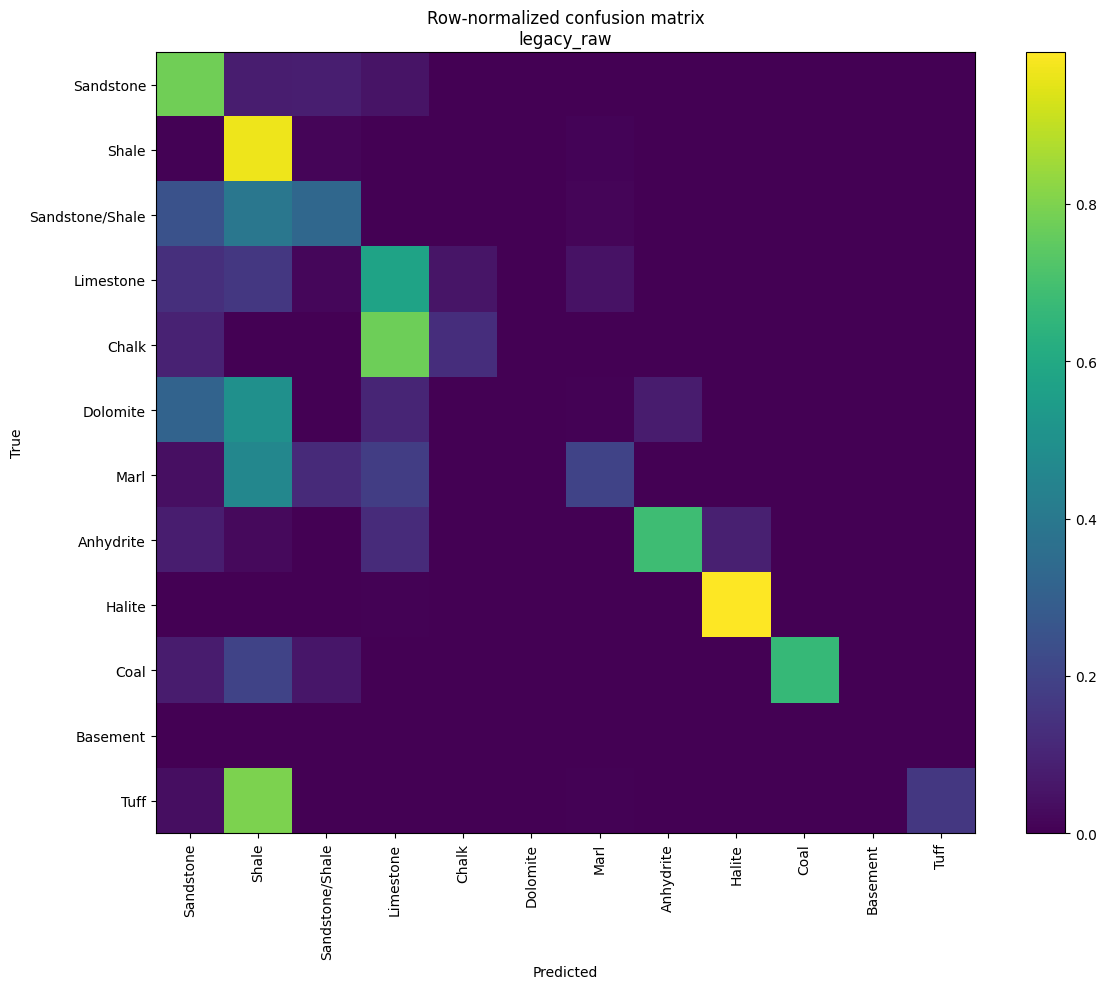

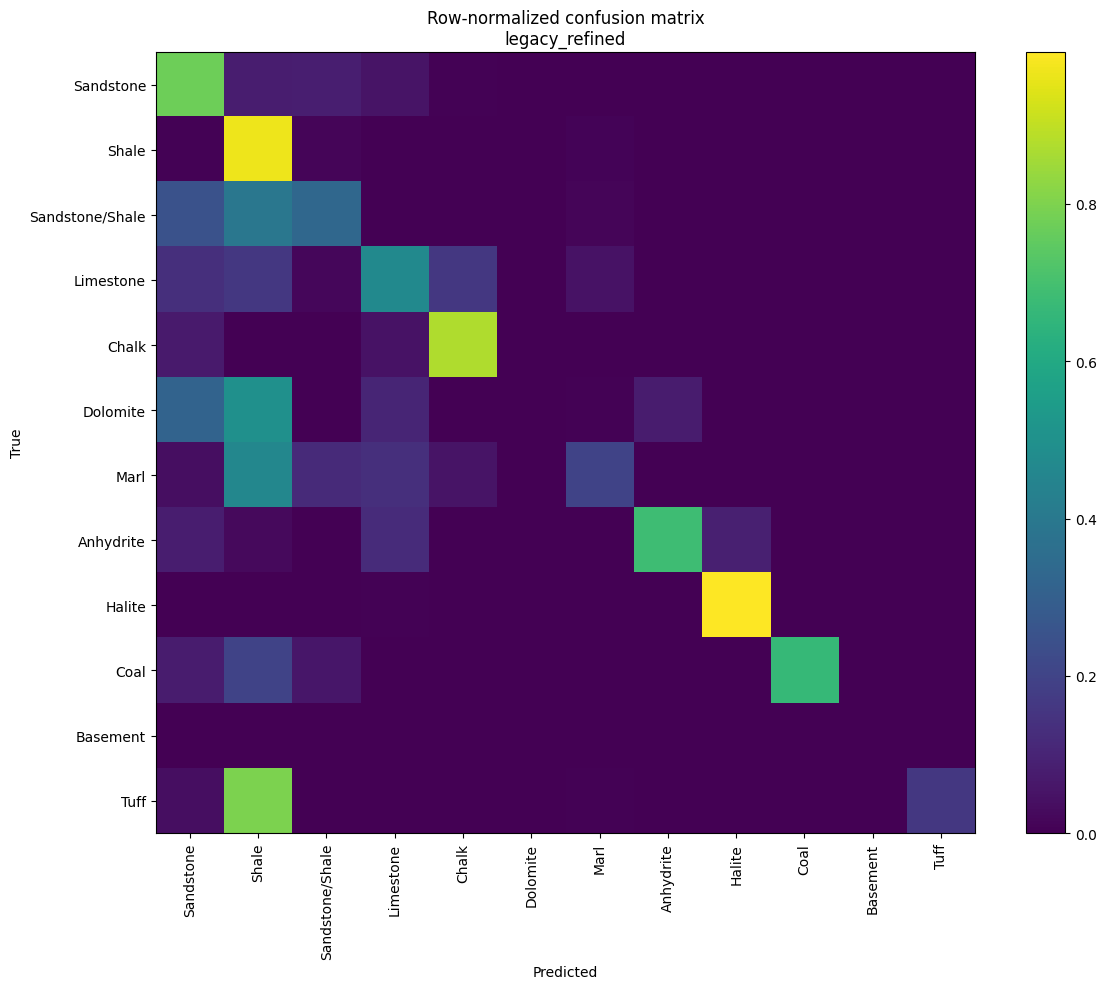

In [17]:
def save_confusion_matrix(
    y_true,
    y_pred,
    variant_name,
):
    matrix = confusion_matrix(
        y_true,
        y_pred,
        labels=CLASS_INDICES,
    )

    matrix_df = pd.DataFrame(
        matrix,
        index=[
            CLASS_INDEX_TO_NAME[index]
            for index in CLASS_INDICES
        ],
        columns=[
            CLASS_INDEX_TO_NAME[index]
            for index in CLASS_INDICES
        ],
    )

    matrix_df.to_csv(
        OUTPUT_DIR
        / (
            f"confusion_matrix_"
            f"{variant_name}_counts.csv"
        )
    )

    row_sums = matrix.sum(
        axis=1,
        keepdims=True,
    )

    normalized = np.divide(
        matrix,
        row_sums,
        out=np.zeros_like(
            matrix,
            dtype=float,
        ),
        where=row_sums > 0,
    )

    normalized_df = pd.DataFrame(
        normalized,
        index=matrix_df.index,
        columns=matrix_df.columns,
    )

    normalized_df.to_csv(
        OUTPUT_DIR
        / (
            f"confusion_matrix_"
            f"{variant_name}_normalized.csv"
        )
    )

    plt.figure(
        figsize=(12, 10)
    )

    image = plt.imshow(
        normalized,
        aspect="auto",
    )

    plt.colorbar(image)

    plt.xticks(
        range(len(CLASS_INDICES)),
        [
            CLASS_INDEX_TO_NAME[index]
            for index in CLASS_INDICES
        ],
        rotation=90,
    )

    plt.yticks(
        range(len(CLASS_INDICES)),
        [
            CLASS_INDEX_TO_NAME[index]
            for index in CLASS_INDICES
        ],
    )

    plt.xlabel("Predicted")
    plt.ylabel("True")

    plt.title(
        f"Row-normalized confusion matrix\n"
        f"{variant_name}"
    )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / (
            f"confusion_matrix_"
            f"{variant_name}.png"
        ),
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()


save_confusion_matrix(
    y_test,
    raw_predictions,
    "legacy_raw",
)

save_confusion_matrix(
    y_test,
    legacy_refined_predictions,
    "legacy_refined",
)

# 15. Feature Importance

In [18]:
feature_importance = pd.DataFrame({
    "feature_position": list(
        range(
            len(
                LEGACY_FEATURE_COLUMNS
            )
        )
    ),
    "feature": (
        LEGACY_FEATURE_COLUMNS
    ),
    "importance": (
        model.feature_importances_
    ),
}).sort_values(
    "importance",
    ascending=False,
)

display(
    feature_importance.head(20)
)

,feature_position,feature,importance
2,2,Y_LOC,0.075374
0,0,GR_NPHI_interaction,0.070549
1,1,GR_DTC_interaction,0.064638
25,25,Shale_indicator,0.061242
5,5,X_LOC,0.060577
16,16,X_LOC,0.060343
8,8,Z_LOC,0.053239
11,11,DEPTH_MD,0.051267
10,10,DEPTH_NORMALIZED,0.051028
3,3,GR_RHOB_RATIO,0.044773


In [19]:
raw_accuracy = (
    raw_metrics["accuracy"]
)

refined_accuracy = (
    legacy_refined_metrics[
        "accuracy"
    ]
)

raw_gate_passed = (
    abs(
        raw_accuracy
        - EXPECTED_RAW_ACCURACY
    )
    <= ACCURACY_TOLERANCE
)

refined_gate_passed = (
    abs(
        refined_accuracy
        - EXPECTED_REFINED_ACCURACY
    )
    <= ACCURACY_TOLERANCE
)

reproduction_gate = {
    "expected_raw_accuracy": (
        EXPECTED_RAW_ACCURACY
    ),
    "observed_raw_accuracy": (
        raw_accuracy
    ),
    "raw_tolerance": (
        ACCURACY_TOLERANCE
    ),
    "raw_gate_passed": bool(
        raw_gate_passed
    ),
    "expected_refined_accuracy": (
        EXPECTED_REFINED_ACCURACY
    ),
    "observed_refined_accuracy": (
        refined_accuracy
    ),
    "refined_tolerance": (
        ACCURACY_TOLERANCE
    ),
    "refined_gate_passed": bool(
        refined_gate_passed
    ),
    "overall_reproduction_passed": bool(
        raw_gate_passed
        and refined_gate_passed
    ),
}

print(
    json.dumps(
        reproduction_gate,
        indent=2,
    )
)

if not reproduction_gate[
    "overall_reproduction_passed"
]:
    print(
        "\n⚠️ Reproduction gate did not pass. "
        "Do not continue to the corrected or causal model "
        "until the discrepancy is audited."
    )
else:
    print(
        "\n✅ Exact legacy reproduction gate passed."
    )

{
  "expected_raw_accuracy": 0.7976,
  "observed_raw_accuracy": 0.797944394061946,
  "raw_tolerance": 0.005,
  "raw_gate_passed": true,
  "expected_refined_accuracy": 0.8069,
  "observed_refined_accuracy": 0.8077648961984363,
  "refined_tolerance": 0.005,
  "refined_gate_passed": true,
  "overall_reproduction_passed": true
}

✅ Exact legacy reproduction gate passed.


In [20]:
class_mapping.to_csv(
    OUTPUT_DIR
    / "00_class_mapping.csv",
    index=False,
)

run_summary.to_csv(
    OUTPUT_DIR
    / "01_run_summary.csv",
    index=False,
)

raw_report_df.to_csv(
    OUTPUT_DIR
    / "02_classification_report_raw.csv",
    index=False,
)

legacy_refined_report_df.to_csv(
    OUTPUT_DIR
    / "03_classification_report_legacy_refined.csv",
    index=False,
)

text_consistent_report_df.to_csv(
    OUTPUT_DIR
    / "04_classification_report_text_consistent.csv",
    index=False,
)

resampling_audit.to_csv(
    OUTPUT_DIR
    / "05_resampling_audit.csv",
    index=False,
)

feature_registry = pd.DataFrame({
    "feature_position": list(
        range(
            len(
                LEGACY_FEATURE_COLUMNS
            )
        )
    ),
    "feature": (
        LEGACY_FEATURE_COLUMNS
    ),
    "is_duplicate_name": (
        pd.Series(
            LEGACY_FEATURE_COLUMNS
        ).duplicated(
            keep=False
        ).to_numpy()
    ),
})

feature_registry.to_csv(
    OUTPUT_DIR
    / "06_legacy_feature_registry.csv",
    index=False,
)

refinement_audit.to_csv(
    OUTPUT_DIR
    / "07_refinement_audit.csv",
    index=False,
)

feature_importance.to_csv(
    OUTPUT_DIR
    / "08_feature_importance.csv",
    index=False,
)

with open(
    OUTPUT_DIR
    / "09_reproduction_gate.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        reproduction_gate,
        file,
        ensure_ascii=False,
        indent=2,
    )

prediction_output = (
    test_metadata.copy()
)

prediction_output[
    "raw_prediction_index"
] = raw_predictions

prediction_output[
    "legacy_refined_prediction_index"
] = (
    legacy_refined_predictions
)

prediction_output[
    "text_consistent_prediction_index"
] = (
    text_consistent_predictions
)

prediction_output[
    "legacy_modified"
] = legacy_change_mask

prediction_output[
    "text_consistent_modified"
] = (
    text_consistent_change_mask
)

for class_index, class_code in enumerate(
    CLASS_CODES
):
    prediction_output[
        f"prob_{class_code}"
    ] = raw_probabilities[
        :,
        class_index,
    ]

prediction_output.to_parquet(
    OUTPUT_DIR
    / "10_test_predictions_probabilities.parquet",
    index=False,
)

joblib.dump(
    scaler,
    ARTIFACT_DIR
    / "legacy_standard_scaler.joblib",
    compress=3,
)

joblib.dump(
    train_imputers,
    ARTIFACT_DIR
    / "legacy_train_imputers.joblib",
    compress=3,
)

run_configuration = {
    "track": "legacy_exact_reproduction",
    "train_path": str(
        TRAIN_PATH
    ),
    "test_path": str(
        TEST_PATH
    ),
    "test_used_for_final_legacy_reproduction": True,
    "train_rows_raw": int(
        len(train_raw)
    ),
    "train_rows_after_legacy_resampling": int(
        len(X_train)
    ),
    "test_rows": int(
        len(X_test)
    ),
    "random_forest": {
        "n_estimators": (
            RF_N_ESTIMATORS
        ),
        "max_depth": (
            RF_MAX_DEPTH
        ),
        "min_samples_split": (
            RF_MIN_SAMPLES_SPLIT
        ),
        "min_samples_leaf": (
            RF_MIN_SAMPLES_LEAF
        ),
        "random_state": (
            RANDOM_STATE_MODEL
        ),
        "n_jobs": RF_N_JOBS,
    },
    "feature_column_count": int(
        len(
            LEGACY_FEATURE_COLUMNS
        )
    ),
    "unique_feature_name_count": int(
        len(
            set(
                LEGACY_FEATURE_COLUMNS
            )
        )
    ),
    "duplicate_feature_names": [
        "X_LOC"
    ],
    "legacy_behavior": {
        "test_depth_normalization_uses_test_min_max": True,
        "train_weak_features_without_WELL": True,
        "test_weak_features_with_WELL": True,
        "basement_added_in_dolomite_branch": True,
        "refinement_condition": (
            "second-ranked class is Chalk"
        ),
    },
    "timing_seconds": {
        "scaling": float(
            scaling_seconds
        ),
        "training": float(
            fit_seconds
        ),
        "prediction": float(
            prediction_seconds
        ),
    },
    "save_model": bool(
        SAVE_MODEL
    ),
}

with open(
    OUTPUT_DIR
    / "11_run_configuration.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        run_configuration,
        file,
        ensure_ascii=False,
        indent=2,
    )

if SAVE_MODEL:
    print(
        "Saving Random Forest model. "
        "This can take considerable time and disk space."
    )

    joblib.dump(
        model,
        ARTIFACT_DIR
        / "legacy_exact_random_forest.joblib",
        compress=3,
    )

print("All outputs saved in:")
print(OUTPUT_DIR)

All outputs saved in:
<historical-output-root>/02A_legacy_RF_exact_reproduction
